# Panel flutter analysis

This example finds the flutter onset of a laminated panel in a supersonic flow, with and without an in-plane pre-stress, by tracing its natural frequencies as the aerodynamic pressure grows.

The aerodynamic load of the linear piston theory is proportional to the slope of the panel along the flow, $q = \beta w_{,x} + \gamma w$ for a flow along $x$. The aerodynamic pressure parameter is $\beta$, and $\gamma$ is the curvature correction of Krumhaar (1963), which softens a cylindrical shell. The load gives the aerodynamic stiffness matrix, `Shell.calc_kA`, a function of the attribute `beta` of the `Shell` object:

$$
\boldsymbol{K}_A = -\int \left(\beta (\boldsymbol{S}^w_{,x})^\top \boldsymbol{S}^w + \gamma (\boldsymbol{S}^w)^\top \boldsymbol{S}^w\right) dA,
$$

with the row $\boldsymbol{S}^w$ of the approximation functions of $w$. $\boldsymbol{K}_A$ is not symmetric. The natural frequencies follow from

$$
(\boldsymbol{K}_C + \boldsymbol{K}_G + \boldsymbol{K}_A + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}, \qquad \lambda^2 = -\omega^2,
$$

solved with `structsolve.freq`. As $\beta$ increases, two natural frequencies approach each other and coalesce. Beyond that point the eigenvalues are complex conjugates, and the panel flutters. The flutter onset is the first $\beta$ with a complex frequency.

The term in $\beta$ is the transpose of that of Eq. (21) of Castro et al. (2016). For $w = 0$ at the leading and trailing edges, this corresponds to reversing the flow direction and does not change the flutter boundary. The sign of the term in $\gamma$ of Eqs. (21) and (29) of that paper is reversed, a mistake of the paper. The aerodynamic damping, `Shell.calc_cA`, is $i \boldsymbol{C}_A$ with $\boldsymbol{C}_A$ of Eq. (23) of the paper, entering the eigenvalue problem as $+\omega \boldsymbol{C}_A$; it is not used here. See also [Aeroelasticity](../aeroelasticity.rst).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import freq
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Panel and frequency sweep

The simply supported plate of $1 \times 0.5$ m has the laminate $[0/90/-45/+45]$ of carbon/epoxy plies of 0.125 mm and density 1500 kg/m³. The sweep uses the non-dimensional parameter $\beta^* = \beta a^3/(E_{22} h^3)$ and the non-dimensional frequencies $\bar{\omega} = \omega a^2 \sqrt{\rho/E_{22}}/(\pi^2 h)$. $\boldsymbol{K}_C$, $\boldsymbol{K}_G$ and $\boldsymbol{M}$ do not depend on $\beta$ and are computed once.

In [2]:
E2 = 8.7e9


def flutter_sweep(model, pre_stress, betasstar):
    s = Shell(model=model, a=1., b=0.5, r=1.e8, stack=[0, 90, -45, +45],
              plyt=0.125e-3, rho=1.5e3, m=8, n=9,
              laminaprop=(142.5e9, E2, 0.28, 5.1e9, 5.1e9, 5.1e9))
    s.Nxx = -60. if pre_stress else 0.
    s.Nyy = -5. if pre_stress else 0.
    h = len(s.stack)*s.plyt
    betas = betasstar*E2*h**3/s.a**3
    s.beta = betas[0]
    kC = s.calc_kC()
    kG = s.calc_kG()
    kM = s.calc_kM()
    omegas = []
    for beta in betas:
        s.beta = beta
        eigvals, eigvecs = freq(kC + kG + s.calc_kA(), kM, sparse_solver=True,
                                silent=True)
        omegan = (-eigvals)**0.5
        omegas.append(omegan*s.a**2/(np.pi**2*h)*np.sqrt(s.rho/E2))
    omegas = np.array(omegas)
    onset = np.where(np.any(omegas.imag != 0, axis=1))[0][0]
    return betas, omegas, onset


betasstar = np.linspace(300, 690, 40)
betas, omegas, onset = flutter_sweep('plate_clpt_donnell', False, betasstar)
print('flutter onset: beta* = %.2f, beta = %.4f' % (betasstar[onset],
                                                   betas[onset]))

flutter onset: beta* = 330.00, beta = 358.8750


The real parts of the first non-dimensional frequencies against $\beta^*$: the first two approach each other and coalesce at the flutter onset (dashed line).

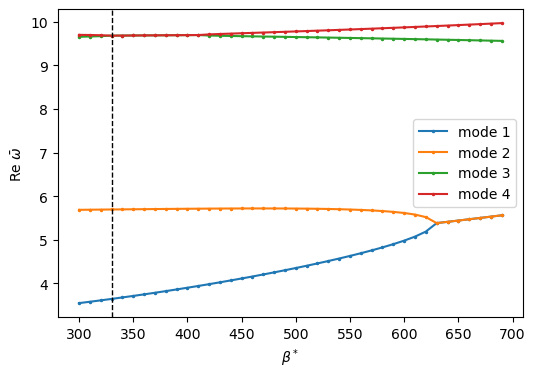

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for j in range(4):
    ax.plot(betasstar, omegas[:, j].real, '.-', ms=3, label='mode %d' % (j + 1))
ax.axvline(betasstar[onset], ls='--', color='k', lw=1)
ax.set_xlabel(r'$\beta^*$')
ax.set_ylabel(r'Re $\bar{\omega}$')
ax.legend()
plt.show()

## Five models, with and without pre-stress

The compressive pre-stress $N_{xx} = -60$ N/m, $N_{yy} = -5$ N/m lowers the stiffness and the flutter onset. The sweep with pre-stress starts at a lower $\beta^*$. The flutter onset is resolved to the step of the sweep, about 10 in $\beta^*$.

The reference values are regression values of $\beta$ from the panels unit test `tests/tests_shell/test_aero.py`, checked there within an absolute tolerance of 0.1.

In [4]:
REF = {False: 358.875, True: 129.663}
SWEEP = {False: np.linspace(300, 690, 40), True: np.linspace(50, 350, 40)}
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    for pre_stress in (False, True):
        betas, omegas, onset = flutter_sweep(model, pre_stress,
                                             SWEEP[pre_stress])
        print('%-22s pre-stress %-5s: onset beta* = %.2f, beta = %.4f'
              % (model, pre_stress, SWEEP[pre_stress][onset], betas[onset]))
        rows.append(('`%s`, pre-stress %s, $\\beta$ at the onset'
                     % (model, pre_stress), betas[onset], REF[pre_stress],
                     'regression value, `test_aero.py`'))
results_table(rows)

plate_clpt_donnell     pre-stress False: onset beta* = 330.00, beta = 358.8750


plate_clpt_donnell     pre-stress True : onset beta* = 119.23, beta = 129.6635


cylshell_clpt_donnell  pre-stress False: onset beta* = 330.00, beta = 358.8750


cylshell_clpt_donnell  pre-stress True : onset beta* = 119.23, beta = 129.6635


cylshell_clpt_sanders  pre-stress False: onset beta* = 330.00, beta = 358.8750


cylshell_clpt_sanders  pre-stress True : onset beta* = 119.23, beta = 129.6635


plate_fsdt_donnell     pre-stress False: onset beta* = 330.00, beta = 358.8750


plate_fsdt_donnell     pre-stress True : onset beta* = 119.23, beta = 129.6635


plate_tsdt_donnell     pre-stress False: onset beta* = 330.00, beta = 358.8750


plate_tsdt_donnell     pre-stress True : onset beta* = 119.23, beta = 129.6635


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, pre-stress False, $\beta$ at the onset | 358.875 | 358.875 | +0.00e+00 | regression value, `test_aero.py` |
| `plate_clpt_donnell`, pre-stress True, $\beta$ at the onset | 129.663 | 129.663 | +3.56e-06 | regression value, `test_aero.py` |
| `cylshell_clpt_donnell`, pre-stress False, $\beta$ at the onset | 358.875 | 358.875 | +0.00e+00 | regression value, `test_aero.py` |
| `cylshell_clpt_donnell`, pre-stress True, $\beta$ at the onset | 129.663 | 129.663 | +3.56e-06 | regression value, `test_aero.py` |
| `cylshell_clpt_sanders`, pre-stress False, $\beta$ at the onset | 358.875 | 358.875 | +0.00e+00 | regression value, `test_aero.py` |
| `cylshell_clpt_sanders`, pre-stress True, $\beta$ at the onset | 129.663 | 129.663 | +3.56e-06 | regression value, `test_aero.py` |
| `plate_fsdt_donnell`, pre-stress False, $\beta$ at the onset | 358.875 | 358.875 | +0.00e+00 | regression value, `test_aero.py` |
| `plate_fsdt_donnell`, pre-stress True, $\beta$ at the onset | 129.663 | 129.663 | +3.56e-06 | regression value, `test_aero.py` |
| `plate_tsdt_donnell`, pre-stress False, $\beta$ at the onset | 358.875 | 358.875 | +0.00e+00 | regression value, `test_aero.py` |
| `plate_tsdt_donnell`, pre-stress True, $\beta$ at the onset | 129.663 | 129.663 | +3.56e-06 | regression value, `test_aero.py` |

## References

1. S. G. P. Castro, T. A. M. Guimarães, D. A. Rade and M. V. Donadon, "Flutter of stiffened composite panels considering the stiffener's base as a structural element". Composite Structures, 140:36-43, 2016. https://doi.org/10.1016/j.compstruct.2015.12.056.
2. H. Krumhaar, "The accuracy of linear piston theory when applied to cylindrical shells". AIAA Journal, 1(6):1448-1449, 1963. https://doi.org/10.2514/3.1832.